Remove duplicates

In [1]:
import hashlib
from pathlib import Path
import pandas as pd

RAW = Path("../data/raw/dataset")
OUT = Path("../outputs")

# 1) Index all images (path, split, label)
rows = []
for split in ["train", "test"]:
    for p in (RAW / split).rglob("*"):
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            rows.append({"path": str(p), "split": split, "label": p.parent.name})
df = pd.DataFrame(rows)
print("Total images:", len(df))   # expected: 3400

# 2) Compute the MD5 hash of each image
def md5_of(f):
    with open(f, "rb") as fh:
        return hashlib.md5(fh.read()).hexdigest()

df["md5"] = df["path"].apply(md5_of)

# 3) Exact duplicates with conflicting labels -> drop the whole group
conflict = df.groupby("md5")["label"].nunique()
conflict_hashes = conflict[conflict > 1].index
print("Conflicting-label duplicate groups:", len(conflict_hashes))
df = df[~df["md5"].isin(conflict_hashes)]

# 4) Keep one copy per hash group, preferring the train copy
#    (so duplicates that appear in test are removed -> no data leakage)
df["split_rank"] = (df["split"] == "test").astype(int)
df = df.sort_values(["md5", "split_rank", "path"])
clean = df.drop_duplicates("md5", keep="first").drop(columns="split_rank")

print("After dedup:", len(clean), "| removed:", len(df) - len(clean))
print(clean.groupby(["split", "label"]).size().unstack(0))

# 5) Save the clean index (raw files are NOT deleted)
clean.to_csv(OUT / "step1_clean_index.csv", index=False)

Total images: 3400
Conflicting-label duplicate groups: 0
After dedup: 3306 | removed: 94
split               test  train
label                          
Healthy              201    771
aculus_olearius      195    681
olive_peacock_spot   260   1198


Create Validation set

In [2]:
from sklearn.model_selection import train_test_split

# Load the clean index from step 1
clean = pd.read_csv(OUT / "step1_clean_index.csv")

# Separate the provided test set (kept untouched)
test_df = clean[clean["split"] == "test"].copy()
train_full = clean[clean["split"] == "train"].copy()

# Stratified 85/15 split of train into train/val
train_df, val_df = train_test_split(
    train_full,
    test_size=0.15,
    stratify=train_full["label"],
    random_state=42,
)

# Update the split column
train_df["split"] = "train"
val_df["split"] = "val"

# Summary
final = pd.concat([train_df, val_df, test_df]).reset_index(drop=True)
print(final.groupby(["split", "label"]).size().unstack(0))
print("\nTotals:", final["split"].value_counts().to_dict())

# Save
final.to_csv(OUT / "step2_split_index.csv", index=False)

split               test  train  val
label                               
Healthy              201    655  116
aculus_olearius      195    579  102
olive_peacock_spot   260   1018  180

Totals: {'train': 2252, 'test': 656, 'val': 398}


Resize to 224 x 224

100%|██████████| 3306/3306 [00:39<00:00, 83.12it/s] 


Processed image size: (224, 224) | mode: RGB


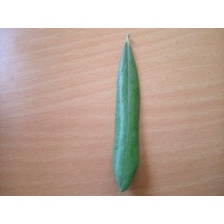

In [3]:
from PIL import Image
from tqdm import tqdm

SIZE = 224
PROC = Path("../data/processed")

# Load the split index from step 2
final = pd.read_csv(OUT / "step2_split_index.csv")

def resize_with_padding(img, size=SIZE, fill=(255, 255, 255)):
    img = img.convert("RGB")
    w, h = img.size
    scale = size / max(w, h)                       # keep aspect ratio
    new_w, new_h = round(w * scale), round(h * scale)
    img = img.resize((new_w, new_h), Image.LANCZOS)
    canvas = Image.new("RGB", (size, size), fill)  # white square canvas
    canvas.paste(img, ((size - new_w) // 2, (size - new_h) // 2))
    return canvas

new_paths = []
for _, row in tqdm(final.iterrows(), total=len(final)):
    dst_dir = PROC / row["split"] / row["label"]
    dst_dir.mkdir(parents=True, exist_ok=True)
    dst = dst_dir / Path(row["path"]).name
    resize_with_padding(Image.open(row["path"])).save(dst, quality=95)
    new_paths.append(str(dst))

final["proc_path"] = new_paths
final.to_csv(OUT / "step3_processed_index.csv", index=False)

# Quick check on a random processed image
sample = Image.open(final["proc_path"].sample(1, random_state=1).iloc[0])
print("Processed image size:", sample.size, "| mode:", sample.mode)
sample

Normalisation

In [4]:
import numpy as np

# Load the processed index from step 3
final = pd.read_csv(OUT / "step3_processed_index.csv")

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def load_img(path):
    """Load an image as float32 array with values in [0, 255]."""
    return np.asarray(Image.open(path).convert("RGB"), dtype=np.float32)

def norm_01(arr):
    """Scale to [0, 1] -> baseline CNN and SVM features."""
    return arr / 255.0

def norm_imagenet(arr):
    """Scale to [0, 1] then apply ImageNet mean/std -> ResNet50 / EfficientNetB0."""
    return (arr / 255.0 - IMAGENET_MEAN) / IMAGENET_STD

# Sanity check on one image
x = load_img(final["proc_path"].iloc[0])
a, b = norm_01(x), norm_imagenet(x)
print("raw      :", x.shape, x.min(), x.max())
print("[0,1]    :", a.min().round(3), a.max().round(3))
print("imagenet :", b.min().round(3), b.max().round(3), "| mean:", b.mean().round(3))

raw      : (224, 224, 3) 14.0 255.0
[0,1]    : 0.055 1.0
imagenet : -1.604 2.64 | mean: 1.494


Class Weights

In [5]:
import json
from sklearn.utils.class_weight import compute_class_weight

train_labels = final.loc[final["split"] == "train", "label"]

# Fixed class order -> integer index (reused in training)
classes = sorted(train_labels.unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

# Balanced weights computed on the training set only
weights = compute_class_weight(class_weight="balanced", classes=np.array(classes), y=train_labels)
class_weights = {class_to_idx[c]: float(w) for c, w in zip(classes, weights)}

print("class_to_idx :", class_to_idx)
print("class_weights:", {c: round(class_weights[i], 3) for c, i in class_to_idx.items()})

# Save for the training stage
with open(OUT / "class_info.json", "w") as f:
    json.dump({"class_to_idx": class_to_idx, "class_weights": class_weights}, f, indent=2)

class_to_idx : {'Healthy': 0, 'aculus_olearius': 1, 'olive_peacock_spot': 2}
class_weights: {'Healthy': 1.146, 'aculus_olearius': 1.296, 'olive_peacock_spot': 0.737}


Feature extraction

## SVM Feature Extraction

Each image (224×224 RGB, white-padded) is converted into a **6,190-dimensional** feature vector by concatenating three hand-crafted descriptors:

| Feature | Description | Parameters | Dimensions |
|---|---|---|---|
| **HOG** (Histogram of Oriented Gradients) | Captures shape and edge structure (e.g., the outline of spots on the leaf) | Grayscale input, 9 orientations, 16×16 pixels per cell, 2×2 cells per block | 6,084 |
| **Color Histogram** | Captures colour distribution, since colour is a diagnostic cue (yellowing, brown spots) | 32 bins per RGB channel, density-normalised | 96 (3 × 32) |
| **LBP** (Local Binary Patterns) | Captures leaf surface texture (smooth, rough, spotted) | Uniform method, P = 8, R = 1, grayscale input | 10 |
| **Total** | | | **6,190** |

**Scaling:** `StandardScaler` (zero mean, unit variance) is fitted on the training set only and then applied to the validation and test sets, to prevent data leakage.

**Resulting shapes:**

| Split | Samples | Features |
|---|---|---|
| Train | 2,252 | 6,190 |
| Validation | 398 | 6,190 |
| Test | 656 | 6,190 |

In [6]:
from skimage.feature import hog, local_binary_pattern
from skimage.color import rgb2gray
from sklearn.preprocessing import StandardScaler
import joblib

def extract_features(path):
    img = np.asarray(Image.open(path).convert("RGB"))            # uint8, 224x224x3
    gray = rgb2gray(img)

    # HOG: shape/edges
    f_hog = hog(gray, orientations=9, pixels_per_cell=(16, 16),
                cells_per_block=(2, 2), feature_vector=True)

    # Color histogram: 32 bins per RGB channel, normalised
    f_col = np.concatenate([
        np.histogram(img[..., c], bins=32, range=(0, 255), density=True)[0]
        for c in range(3)
    ])

    # LBP (uniform, P=8, R=1): texture
    lbp = local_binary_pattern((gray * 255).astype(np.uint8), P=8, R=1, method="uniform")
    f_lbp = np.histogram(lbp, bins=10, range=(0, 10), density=True)[0]

    return np.concatenate([f_hog, f_col, f_lbp]).astype(np.float32)

def build_split(name):
    d = final[final["split"] == name]
    X = np.stack([extract_features(p) for p in tqdm(d["proc_path"], desc=name)])
    y = d["label"].map(class_to_idx).values
    return X, y

X_train, y_train = build_split("train")
X_val,   y_val   = build_split("val")
X_test,  y_test  = build_split("test")

# StandardScaler: fit on train only, then transform all splits
scaler = StandardScaler().fit(X_train)
X_train, X_val, X_test = (scaler.transform(X) for X in (X_train, X_val, X_test))

print("Feature shapes:", X_train.shape, X_val.shape, X_test.shape)

# Save features and scaler
np.savez_compressed(OUT / "svm_features.npz",
                    X_train=X_train, y_train=y_train,
                    X_val=X_val, y_val=y_val,
                    X_test=X_test, y_test=y_test)
joblib.dump(scaler, OUT / "svm_scaler.joblib")

test: 100%|██████████| 656/656 [00:13<00:00, 49.59it/s]


Feature shapes: (2252, 6190) (398, 6190) (656, 6190)


['..\\outputs\\svm_scaler.joblib']

CSV (train/val/test)

In [7]:
from pathlib import Path
import pandas as pd
import json

OUT = Path("../outputs")
PROC = Path("../data/processed")

final = pd.read_csv(OUT / "step3_processed_index.csv")
with open(OUT / "class_info.json") as f:
    class_to_idx = json.load(f)["class_to_idx"]

final["label_idx"] = final["label"].map(class_to_idx)

# Keep only what is needed for training
cols = ["proc_path", "label", "label_idx", "md5"]
for split in ["train", "val", "test"]:
    d = final[final["split"] == split][cols].reset_index(drop=True)
    d.to_csv(PROC / f"{split}.csv", index=False)
    print(split, d.shape, d["label"].value_counts().to_dict())

# Preprocessing config for reproducibility
config = {
    "image_size": 224,
    "padding": "white",
    "val_fraction": 0.15,
    "seed": 42,
    "dedup": "md5 (train copy preferred)",
    "normalisation": {"baseline_svm": "[0,1]", "pretrained": "ImageNet mean/std"},
    "augmentation": "train only, applied during training",
}
with open(PROC / "preprocessing_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("\nFiles in processed/:", sorted(p.name for p in PROC.iterdir()))

train (2252, 4) {'olive_peacock_spot': 1018, 'Healthy': 655, 'aculus_olearius': 579}
val (398, 4) {'olive_peacock_spot': 180, 'Healthy': 116, 'aculus_olearius': 102}
test (656, 4) {'olive_peacock_spot': 260, 'Healthy': 201, 'aculus_olearius': 195}

Files in processed/: ['preprocessing_config.json', 'test', 'test.csv', 'train', 'train.csv', 'val', 'val.csv']
